<a href="https://colab.research.google.com/github/MandalaYeshwanth19/GEN_AI/blob/main/Week3_Gemini_MongoDB_Logging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install -q -U google-genai pymongo pandas matplotlib

In [ ]:
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GeminiAPIKey5")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key is missing!")

print("Gemini API key configured successfully!")


Gemini API key configured successfully!


In [6]:
from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(
        timeout=30000
    )
)

MODEL_NAME = "gemini-3.1-flash-lite"

print("Gemini client initialized successfully!")


Gemini client initialized successfully!


In [7]:
response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)

At its simplest, **Artificial Intelligence (AI)** is a field of computer science that focuses on building smart machines capable of performing tasks that typically require human intelligence.

Think of it as teaching a computer how to "think," learn, and make decisions rather than just following a strict set of pre-programmed instructions.

Here is a breakdown of what that actually means:

### 1. How does it work?
Traditional software works on "If-Then" rules (e.g., *If* the user clicks this button, *Then* open this window). AI works differently by using **data**. 

Instead of being told exactly what to do, AI is "trained" on massive amounts of information. It looks for patterns in that data to make predictions or decisions. This process is often called **Machine Learning**.

### 2. The Three Levels of AI
To understand the scope of AI, it is often categorized into three stages:

*   **Artificial Narrow Intelligence (ANI):** This is the AI we have today. It is designed to perform one sp

In [9]:
MONGODB_URI = userdata.get("MONGODB_URI")

if not MONGODB_URI:
    raise ValueError("MongoDB connection string is missing!")

print("MongoDB credentials loaded successfully!")


MongoDB credentials loaded successfully!


In [22]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=5000,
    connectTimeoutMS=5000,
    socketTimeoutMS=10000,
    timeoutMS=10000,
    retryWrites=True
)

# Test the database connection
mongo_client.admin.command("ping")

# Create database
db = mongo_client["GenAI_Monitoring"]

# Create collection
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")
print("Database:", db.name)
print("Collection:", collection.name)



MongoDB connected successfully!
Database: GenAI_Monitoring
Collection: api_usage_logs


In [21]:
import requests, socket, ssl

# 1. The IP Colab is using right now
print("Colab IP:", requests.get("https://api.ipify.org").text)

# 2. Raw TLS test against one shard, bypassing pymongo
host = "ac-fsfvyo8-shard-00-00.tqbejhz.mongodb.net"
try:
    with socket.create_connection((host, 27017), timeout=10) as s:
        with ssl.create_default_context().wrap_socket(s, server_hostname=host) as t:
            print("TLS OK:", t.version())
except Exception as e:
    print("TLS failed:", e)

Colab IP: 136.67.81.223
TLS OK: TLSv1.3


In [23]:
import time
import uuid
import random
import pymongo

from datetime import datetime, timezone
from pymongo.errors import PyMongoError


In [12]:
# Gemini 2.5 Flash standard paid-tier pricing
# USD per 1 million tokens

INPUT_PRICE = 0.30
OUTPUT_PRICE = 2.50

def calculate_cost(input_tokens, output_tokens):

    input_cost = (
        input_tokens * INPUT_PRICE / 1_000_000
    )

    output_cost = (
        output_tokens * OUTPUT_PRICE / 1_000_000
    )

    total_cost = input_cost + output_cost

    return total_cost


In [13]:
input_tokens = 1000
output_tokens = 2000

cost = calculate_cost(
    input_tokens,
    output_tokens
)

print("Estimated cost: $", cost)


Estimated cost: $ 0.0053


In [14]:
def retry_delay(attempt):

    delay = min(2 ** (attempt - 1), 16)

    return delay + random.uniform(0, 1)


def is_temporary_error(error):

    status_code = getattr(
        error, "status_code",
        getattr(error, "code", None)
    )

    if status_code in [408, 429, 500, 502, 503, 504]:
        return True

    error_name = type(error).__name__.lower()

    temporary_errors = [
        "timeout",
        "connection",
        "temporarily"
    ]

    return any(
        word in error_name
        for word in temporary_errors
    )


In [15]:
def save_log(record):

    for attempt in range(1, 4):

        try:

            with pymongo.timeout(10):

                collection.update_one(
                    {"_id": record["_id"]},
                    {"$setOnInsert": record},
                    upsert=True
                )

            print("Log saved in MongoDB!")
            return True

        except PyMongoError as error:

            print(
                f"MongoDB error: {error}"
            )

            if attempt == 3:
                print("Unable to save the log.")
                return False

            time.sleep(retry_delay(attempt))

    return False


In [16]:
def ask_gemini(prompt):
    request_id = str(uuid.uuid4())
    MAX_RETRIES = 4

    for attempt in range(1, MAX_RETRIES + 1):
        start_time = time.perf_counter()

        input_tokens = 0
        output_tokens = 0
        total_tokens = 0
        response_text = ""
        error = None
        error_message = None
        status = "failed"

        try:
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt
            )

            response_text = response.text or ""

            usage = response.usage_metadata

            if usage:
                input_tokens = usage.prompt_token_count or 0
                output_tokens = usage.candidates_token_count or 0
                total_tokens = usage.total_token_count or 0

            status = "success"

        except Exception as e:
            error = e
            error_message = str(e)
            print(f"API attempt {attempt} failed: {error_message}")

        latency = time.perf_counter() - start_time

        estimated_cost = calculate_cost(input_tokens, output_tokens)

        log_record = {
            "_id": f"{request_id}_{attempt}",
            "request_id": request_id,
            "timestamp": datetime.now(timezone.utc),
            "model": MODEL_NAME,
            "prompt": prompt,
            "attempt": attempt,
            "input_tokens": input_tokens,
            "output_tokens": output_tokens,
            "total_tokens": total_tokens,
            "latency_seconds": round(latency, 3),
            "estimated_cost_usd": round(estimated_cost, 10),
            "status": status,
            "error": error_message
        }

        save_log(log_record)

        print("\n========== API MONITORING ==========")
        print("Request ID:", request_id)
        print("Attempt:", attempt)
        print("Status:", status)
        print("Input Tokens:", input_tokens)
        print("Output Tokens:", output_tokens)
        print("Total Tokens:", total_tokens)
        print("Latency:", round(latency, 3), "seconds")
        print("Estimated Cost: $", estimated_cost)

        if status == "success":
            print("\n========== GEMINI RESPONSE ==========")
            print(response_text)
            return response_text

        if attempt == MAX_RETRIES or not is_temporary_error(error):
            print("\nRequest failed permanently.")
            break

        wait_time = retry_delay(attempt)
        print(f"Retrying after {wait_time:.2f} seconds...")
        time.sleep(wait_time)

    return None

In [24]:
while True:

    prompt = input("\nEnter your question (or type exit): ")

    if prompt.lower() == "exit":
        print("Application stopped.")
        break

    if not prompt.strip():
        print("Please enter a valid question.")
        continue

    ask_gemini(prompt)



Enter your question (or type exit): what is AI?
Log saved in MongoDB!

========== API MONITORING ==========
Request ID: 729d51ae-4916-42e6-a8be-86dc0f573802
Attempt: 1
Status: success
Input Tokens: 5
Output Tokens: 687
Total Tokens: 692
Latency: 2.979 seconds
Estimated Cost: $ 0.001719

========== GEMINI RESPONSE ==========
At its simplest, **Artificial Intelligence (AI)** is a branch of computer science that aims to create machines or software capable of performing tasks that typically require human intelligence.

Think of it as teaching a computer how to "think," learn, and solve problems rather than just following a rigid set of pre-programmed instructions.

Here is a breakdown to help you understand it better:

---

### 1. How does it work? (The Core Idea)
Traditional software works like a recipe: *If you do A, then do B.* It follows strict rules.

AI works more like a student: You provide it with massive amounts of data, and it looks for patterns. Once it identifies those pattern

In [25]:
records = list(
    collection.find(
        {},
        {"_id": 0}
    ).sort("timestamp", -1)
)

print("Total API attempts:", len(records))

for record in records:

    print("\n--------------------------")

    print("Model:", record["model"])

    print("Input Tokens:", record["input_tokens"])

    print("Output Tokens:", record["output_tokens"])

    print("Total Tokens:", record["total_tokens"])

    print("Latency:", record["latency_seconds"])

    print("Cost:", record["estimated_cost_usd"])

    print("Status:", record["status"])


Total API attempts: 1

--------------------------
Model: gemini-3.1-flash-lite
Input Tokens: 5
Output Tokens: 687
Total Tokens: 692
Latency: 2.979
Cost: 0.001719
Status: success


In [26]:
import pandas as pd

records = list(
    collection.find({}, {"_id": 0})
)

df = pd.DataFrame(records)

if not df.empty:

    display(df)

else:

    print("No records found.")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,attempt,error,estimated_cost_usd,input_tokens,latency_seconds,model,output_tokens,prompt,request_id,status,timestamp,total_tokens
0,1,None,0.001719,5,2.979,gemini-3.1-flash-lite,687,what is AI?,729d51ae-4916-42e6-a8be-86dc0f573802,success,2026-11-14 05:26:53.043,692


In [27]:
pipeline = [
    {
        "$group": {
            "_id": None,
            "total_api_attempts": {"$sum": 1},
            "total_input_tokens": {"$sum": "$input_tokens"},
            "total_output_tokens": {"$sum": "$output_tokens"},
            "total_tokens": {"$sum": "$total_tokens"},
            "average_latency": {"$avg": "$latency_seconds"},
            "total_estimated_cost": {"$sum": "$estimated_cost_usd"}
        }
    }
]

result = list(collection.aggregate(pipeline))

if result:
    summary = result[0]
    print("Total API Attempts:", summary["total_api_attempts"])
    print("Total Input Tokens:", summary["total_input_tokens"])
    print("Total Output Tokens:", summary["total_output_tokens"])
    print("Total Tokens:", summary["total_tokens"])
    print("Average Latency:", round(summary["average_latency"], 3))
    print("Total Estimated Cost: $", summary["total_estimated_cost"])
else:
    print("No API usage data available.")

Total API Attempts: 1
Total Input Tokens: 5
Total Output Tokens: 687
Total Tokens: 692
Average Latency: 2.979
Total Estimated Cost: $ 0.001719


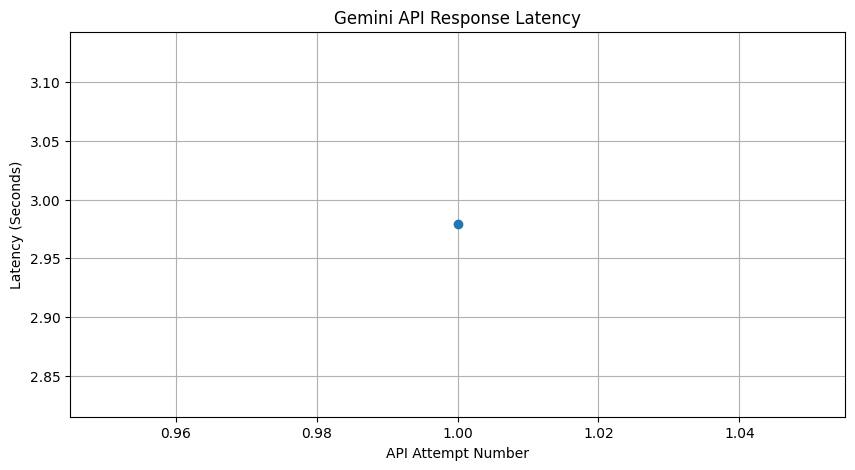

In [28]:
import matplotlib.pyplot as plt

if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.plot(
        range(1, len(df) + 1),
        df["latency_seconds"],
        marker="o"
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Latency (Seconds)")

    plt.title("Gemini API Response Latency")

    plt.grid(True)

    plt.show()


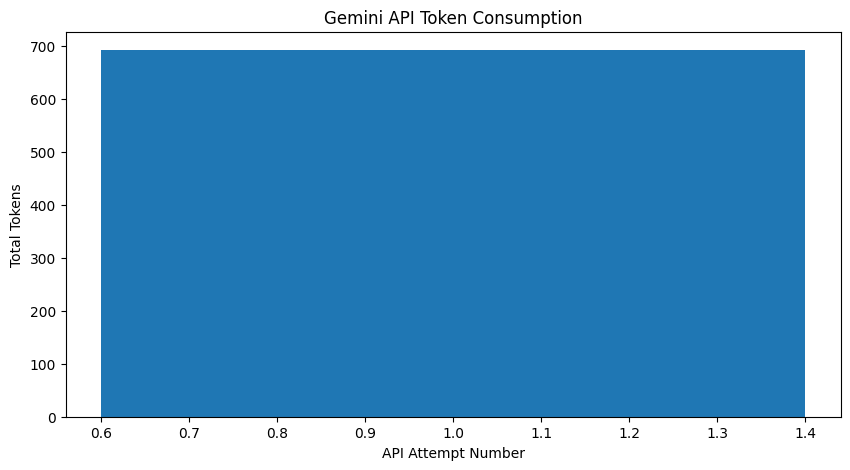

In [29]:
if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.bar(
        range(1, len(df) + 1),
        df["total_tokens"]
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Total Tokens")

    plt.title("Gemini API Token Consumption")

    plt.show()
